<a href="https://colab.research.google.com/github/poggerssLL/Automatica---Grupo-2/blob/main/etapa-03-arvores/aula_24_redes_de_petri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 24 — Modelagem e Verificação Formal em Redes de Petri

Este notebook implementa a modelagem matricial ($C = \text{Post} - \text{Pre}$), a geração da **Árvore de Cobertura/Alcançabilidade** e a **Simulação Discreta** da envasadora de copos, validando:
1. **Cenário A (Sem restrição na esteira `EST-500`):** Detecção automática de crescimento ilimitado ($\omega$).
2. **Cenário B (Com Lugar Complementar $K_{\max} = 3$):** Prova de limitação finita e ausência de *deadlock*.
3. **Modelo Integrado (`M-001`, `E4` e `EST-500`):** Verificação formal de exclusão mútua entre a mesa indexadora e a prensa, além da simulação temporal de ciclos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from collections import deque

np.set_printoptions(linewidth=120)

## 1. Motor de Rede de Petri e Algoritmo de Cobertura (Karp-Miller)

A classe `RedeDePetri` abaixo permite definir qualquer rede via matrizes `Pre` e `Post`, verificar transições habilitadas, construir o grafo de cobertura (detectando $\omega$ quando há crescimento ilimitado) e checar propriedades de limitação e *deadlock*.

In [2]:
OMEGA = float('inf')

def fmt_marking(m):
    return "(" + ", ".join("ω" if x == OMEGA else str(int(x)) for x in m) + ")"

class RedeDePetri:
    def __init__(self, lugares, transicoes, Pre, Post, M0):
        self.lugares = lugares
        self.transicoes = transicoes
        self.Pre = np.array(Pre, dtype=float)
        self.Post = np.array(Post, dtype=float)
        self.C = self.Post - self.Pre
        self.M0 = tuple(float(x) for x in M0)

    def habilitadas(self, M):
        hab = []
        for j in range(len(self.transicoes)):
            if all(M[i] >= self.Pre[i, j] for i in range(len(self.lugares))):
                hab.append(j)
        return hab

    def disparar(self, M, j):
        nova = []
        for i in range(len(self.lugares)):
            if M[i] == OMEGA:
                nova.append(OMEGA)
            else:
                nova.append(M[i] + self.C[i, j])
        return tuple(nova)

    def arvore_cobertura(self, max_nos=200):
        """Constrói o grafo de cobertura (Karp-Miller) detectando ω e deadlocks."""
        visitados = {self.M0}
        arestas = []
        deadlocks = []
        # Fila guarda (marcacao_atual, caminho_ancestrais)
        fila = deque([(self.M0, [self.M0])])

        while fila and len(visitados) < max_nos:
            M, ancestrais = fila.popleft()
            hab = self.habilitadas(M)
            if not hab:
                deadlocks.append(M)
                continue

            for j in hab:
                M_next = list(self.disparar(M, j))
                # Verifica dominância estrita sobre algum ancestral (introdução de ω)
                for anc in ancestrais:
                    if all(M_next[i] >= anc[i] for i in range(len(M_next))) and \
                       any(M_next[i] > anc[i] for i in range(len(M_next))):
                        for i in range(len(M_next)):
                            if M_next[i] > anc[i]:
                                M_next[i] = OMEGA
                M_next = tuple(M_next)
                arestas.append((M, M_next, self.transicoes[j]))

                if M_next not in visitados:
                    visitados.add(M_next)
                    fila.append((M_next, ancestrais + [M_next]))

        tem_omega = any(OMEGA in m for m in visitados)
        return visitados, arestas, deadlocks, tem_omega

## 2. Subsistema da Esteira `EST-500`: Sem Limite ($\omega$) vs. Lugar Complementar ($K_{\max} = 3$)

Aqui reproduzimos exatamente a fronteira ilustrada no **Slide 7**.

In [3]:
# --- CENÁRIO A: Esteira EST-500 SEM limite de capacidade ---
lugares_A = ["P_IN", "EST-500"]
trans_A = ["T1 (Entrada)", "T2 (Saida)"]

# T1 mantém P_IN ativo (fonte contínua da mesa) e deposita em EST-500
# T2 consome de EST-500
Pre_A  = [[1, 0],
          [0, 1]]
Post_A = [[1, 0],
          [1, 0]]
M0_A   = [1, 0]

rdp_A = RedeDePetri(lugares_A, trans_A, Pre_A, Post_A, M0_A)
est_A, ar_A, dl_A, omega_A = rdp_A.arvore_cobertura()

print("=== CENÁRIO A: EST-500 SEM LIMITE ===")
print("Estados na Árvore de Cobertura:", [fmt_marking(m) for m in est_A])
print(f"Possui crescimento ilimitado (ω)? {omega_A}")
print(f"Deadlocks detectados: {len(dl_A)}\n")

# --- CENÁRIO B: Esteira EST-500 COM Lugar Complementar (K_max = 3) ---
lugares_B = ["P_IN", "EST-500", "VAGAS_EST500"]
trans_B = ["T1 (Entrada)", "T2 (Saida)"]

Pre_B  = [[1, 0],
          [0, 1],
          [1, 0]]
Post_B = [[1, 0],
          [1, 0],
          [0, 1]]
M0_B   = [1, 0, 3]

rdp_B = RedeDePetri(lugares_B, trans_B, Pre_B, Post_B, M0_B)
est_B, ar_B, dl_B, omega_B = rdp_B.arvore_cobertura()

print("=== CENÁRIO B: EST-500 COM LUGAR COMPLEMENTAR (K_max = 3) ===")
print("Estados Alcançáveis:", [fmt_marking(m) for m in sorted(est_B)])
print(f"Total de estados: {len(est_B)} (Rede Finita e 3-limitada)")
print(f"Possui crescimento ilimitado (ω)? {omega_B}")
print(f"Deadlocks detectados: {len(dl_B)}")

=== CENÁRIO A: EST-500 SEM LIMITE ===
Estados na Árvore de Cobertura: ['(1, 0)', '(1, ω)']
Possui crescimento ilimitado (ω)? True
Deadlocks detectados: 0

=== CENÁRIO B: EST-500 COM LUGAR COMPLEMENTAR (K_max = 3) ===
Estados Alcançáveis: ['(1, 0, 3)', '(1, 1, 2)', '(1, 2, 1)', '(1, 3, 0)']
Total de estados: 4 (Rede Finita e 3-limitada)
Possui crescimento ilimitado (ω)? False
Deadlocks detectados: 0


## 3. Modelo Integrado: Exclusão Mútua (`M-001` vs. `E4`) + Buffer `EST-500`

Agora validamos o modelo completo unindo:
* O recurso de exclusão mútua `P_MESA_LIVRE` ($M_0=1$), garantindo que `M-001` (mesa girando) e `E4` (prensa atuando) nunca ocorram ao mesmo tempo.
* O lugar complementar `P_VAGAS_EST500` ($M_0=3$), garantindo que a prensa só descarregue o copo quando houver espaço na esteira `EST-500`.

In [4]:
lugares_int = [
    "P_MESA_LIVRE",    # 0
    "P_M001_GIRANDO",  # 1
    "P_E4_PRENSA",     # 2
    "P_EST500",        # 3
    "P_VAGAS_EST500"   # 4
]

trans_int = [
    "T_INICIO_GIRO",   # 0
    "T_FIM_GIRO",      # 1
    "T_INICIO_E4",     # 2
    "T_FIM_E4",        # 3
    "T_SAIDA_EST500"   # 4
]

# Linhas = Lugares (5), Colunas = Transições (5)
Pre_int = [
    [1, 0, 1, 0, 0],  # P_MESA_LIVRE
    [0, 1, 0, 0, 0],  # P_M001_GIRANDO
    [0, 0, 0, 1, 0],  # P_E4_PRENSA
    [0, 0, 0, 0, 1],  # P_EST500
    [0, 0, 0, 1, 0],  # P_VAGAS_EST500 (T_FIM_E4 exige vaga livre na esteira)
]

Post_int = [
    [0, 1, 0, 1, 0],  # P_MESA_LIVRE
    [1, 0, 0, 0, 0],  # P_M001_GIRANDO
    [0, 0, 1, 0, 0],  # P_E4_PRENSA
    [0, 0, 0, 1, 0],  # P_EST500
    [0, 0, 0, 0, 1],  # P_VAGAS_EST500
]

M0_int = [1, 0, 0, 0, 3]

rdp_int = RedeDePetri(lugares_int, trans_int, Pre_int, Post_int, M0_int)
est_int, ar_int, dl_int, omega_int = rdp_int.arvore_cobertura()

# Verificações Formais sobre TODOS os estados alcançáveis
violacao_exclusao = any((m[1] > 0 and m[2] > 0) for m in est_int)
max_est500 = max(m[3] for m in est_int)
invariante_mesa_ok = all((m[0] + m[1] + m[2] == 1) for m in est_int)
invariante_buffer_ok = all((m[3] + m[4] == 3) for m in est_int)

print("=== VERIFICAÇÃO FORMAL DO MODELO INTEGRADO ===")
print(f"Total de estados alcançáveis : {len(est_int)}")
print(f"Crescimento ilimitado (ω)    : {omega_int}")
print(f"Deadlocks encontrados        : {len(dl_int)}")
print(f"Máximo de copos em EST-500   : {int(max_est500)} (Limite K_max = 3)")
print(f"Violação M-001 + E4 juntos?  : {violacao_exclusao}")
print(f"P-Invariante Mesa (soma=1)   : {invariante_mesa_ok}")
print(f"P-Invariante Buffer (soma=3) : {invariante_buffer_ok}")

=== VERIFICAÇÃO FORMAL DO MODELO INTEGRADO ===
Total de estados alcançáveis : 12
Crescimento ilimitado (ω)    : False
Deadlocks encontrados        : 0
Máximo de copos em EST-500   : 3 (Limite K_max = 3)
Violação M-001 + E4 juntos?  : False
P-Invariante Mesa (soma=1)   : True
P-Invariante Buffer (soma=3) : True


## 4. Visualização do Grafo de Alcançabilidade e Simulação de Ciclos

Abaixo plotamos o grafo de alcançabilidade do Cenário B ($K_{\max}=3$) e executamos uma simulação discreta de 18 eventos no modelo integrado, acompanhando a ocupação da esteira e o intertravamento entre `M-001` e `E4`.

/tmp/ipykernel_1669/2899795106.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


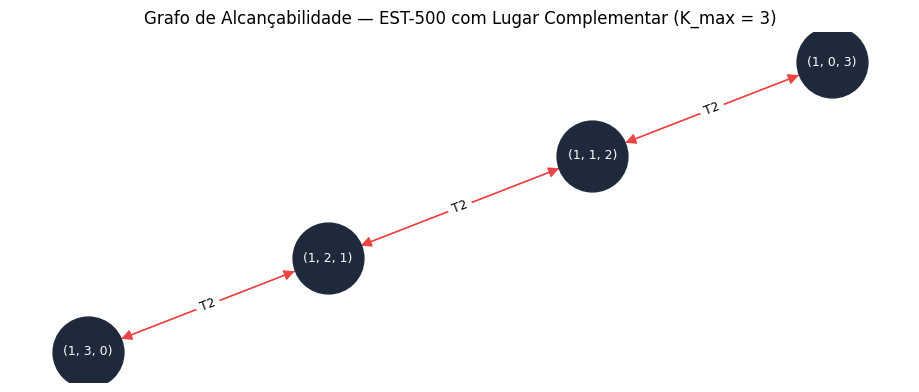

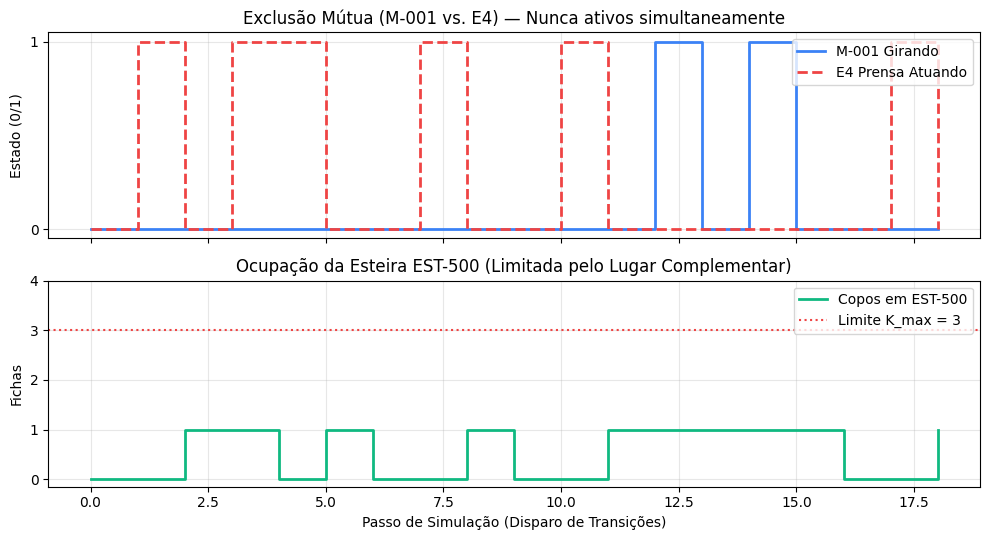

In [5]:
# 1) Plot do Grafo de Alcançabilidade (Cenário B - Esteira K_max = 3)
G = nx.DiGraph()
for u, v, label in ar_B:
    G.add_edge(fmt_marking(u), fmt_marking(v), label=label.split()[0])

plt.figure(figsize=(9, 3.5))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color="#1e293b", font_color="white",
        node_size=2600, font_size=9, edge_color="#ef4444", arrows=True, arrowsize=16)
edge_labels = nx.get_edge_attributes(G, 'label')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9)
plt.title("Grafo de Alcançabilidade — EST-500 com Lugar Complementar (K_max = 3)")
plt.tight_layout()
plt.show()

# 2) Simulação Discreta de Eventos no Modelo Integrado
rng = np.random.default_rng(7)
M_atual = rdp_int.M0
historico_M = [M_atual]
eventos = ["M0"]

for passo in range(18):
    hab = rdp_int.habilitadas(M_atual)
    t_escolhida = int(rng.choice(hab))
    M_atual = rdp_int.disparar(M_atual, t_escolhida)
    historico_M.append(M_atual)
    eventos.append(rdp_int.transicoes[t_escolhida])

hist = np.array(historico_M)
passos = np.arange(len(hist))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)

ax1.step(passos, hist[:, 1], where='post', label="M-001 Girando", color="#3b82f6", linewidth=2)
ax1.step(passos, hist[:, 2], where='post', label="E4 Prensa Atuando", color="#ef4444", linestyle="--", linewidth=2)
ax1.set_yticks([0, 1])
ax1.set_ylabel("Estado (0/1)")
ax1.set_title("Exclusão Mútua (M-001 vs. E4) — Nunca ativos simultaneamente")
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)

ax2.step(passos, hist[:, 3], where='post', label="Copos em EST-500", color="#10b981", linewidth=2)
ax2.axhline(3, color="#ef4444", linestyle=":", label="Limite K_max = 3")
ax2.set_yticks([0, 1, 2, 3, 4])
ax2.set_xlabel("Passo de Simulação (Disparo de Transições)")
ax2.set_ylabel("Fichas")
ax2.set_title("Ocupação da Esteira EST-500 (Limitada pelo Lugar Complementar)")
ax2.legend(loc="upper right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()